In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math

In [40]:
path = "../output-files/clock-mesh/20261022T083342.825648Z_4effaa7f/observations.csv"
df = pd.read_csv(path)

df["unwrapped_dot_timestamp_us"][0:10]

#epoch_count = (df["connection_epoch"] == 0).sum()
#print(epoch_count)

0    25948086
1    25964753
2    25981420
3    25998087
4    26014754
5    26031421
6    26048088
7    26064755
8    26081422
9    26062844
Name: unwrapped_dot_timestamp_us, dtype: int64

In [41]:
# Isolate one DOT
dot = df[
    (df["address"] == "D4:22:CD:07:B4:5E")
].copy()

dot = dot.sort_values("unwrapped_dot_timestamp_us")

# First calibration source timestamp.
dot_t0 = dot["unwrapped_dot_timestamp_us"].iloc[0]

# X: elapsed DOT time in seconds.
dot["dot_elapsed_s"] = (
    dot["unwrapped_dot_timestamp_us"] - dot_t0
) / 1_000_000

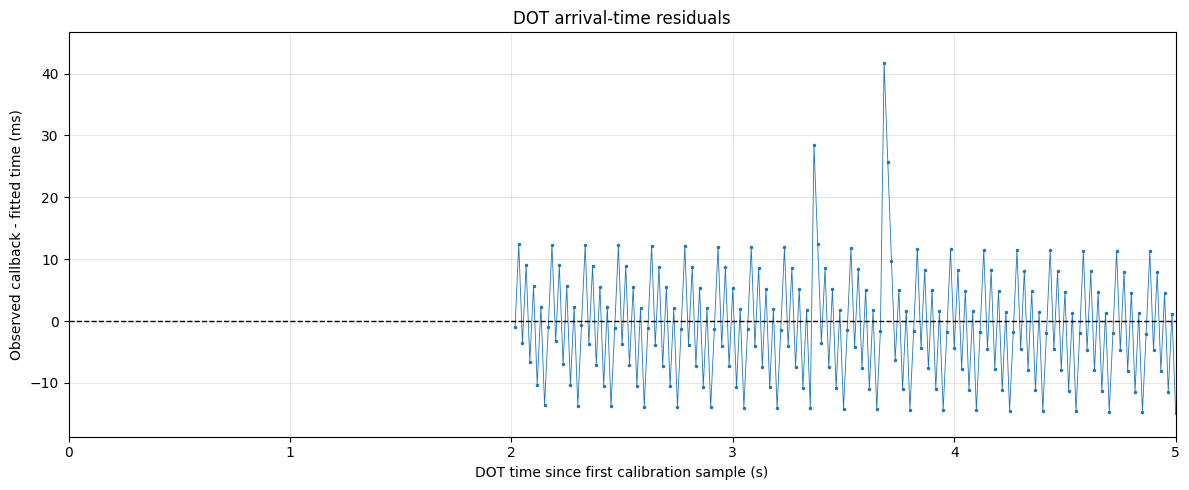

In [42]:
# Keep observations for which ClockMesh has a mapping.
plot_data = dot.dropna(
    subset=["reference_time_ns", "mapped_timestamp_ns"]
).copy()

# Y: observed gateway callback minus mapped time, in ms.
plot_data["residual_ms"] = (
    plot_data["reference_time_ns"]
    - plot_data["mapped_timestamp_ns"]
) / 1_000_000

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    plot_data["dot_elapsed_s"],
    plot_data["residual_ms"],
    ".-",
    markersize=3,
    linewidth=0.6
)

ax.axhline(0, linestyle="--", linewidth=1, color="black")

ax.set_xlabel("DOT time since first calibration sample (s)")
ax.set_ylabel("Observed callback - fitted time (ms)")
ax.set_title("DOT arrival-time residuals")
ax.grid(True, alpha=0.3)

# Examine the first five seconds.
ax.set_xlim(0, 5)

plt.tight_layout()
plt.show()

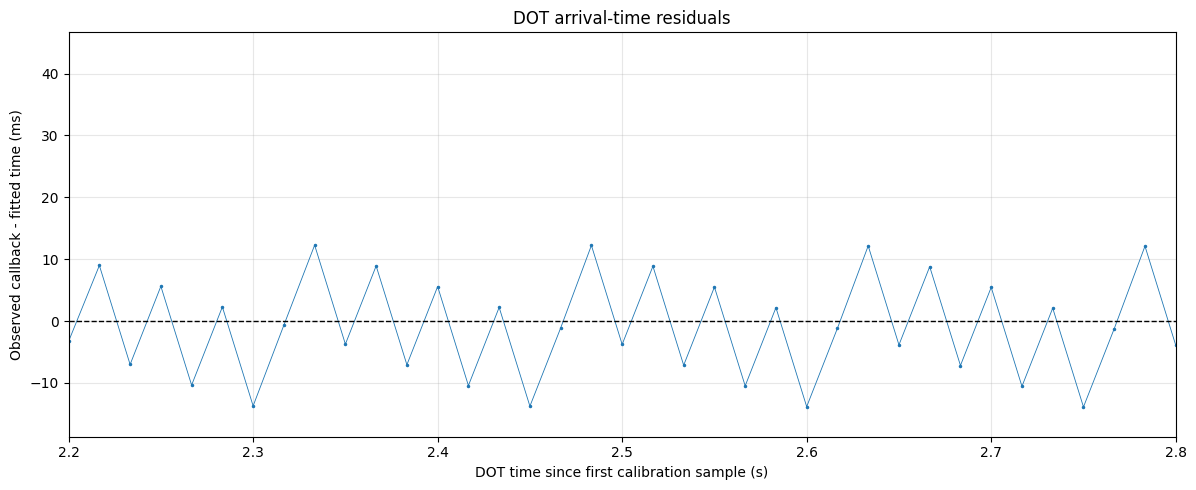

In [43]:
ax.set_xlim(2.2, 2.8)
fig

In [44]:
plot_data["callback_interval_ms"] = (
    plot_data["reference_time_ns"].diff() / 1_000_000
)

plot_data["fitted_interval_ms"] = (
    plot_data["mapped_timestamp_ns"].diff() / 1_000_000
)

plot_data["residual_step_ms"] = (
    plot_data["residual_ms"].diff()
)

print(
    plot_data[
        [
            "dot_elapsed_s",
            "callback_interval_ms",
            "fitted_interval_ms",
            "residual_step_ms",
        ]
    ].head(25).round(3)
)

     dot_elapsed_s  callback_interval_ms  fitted_interval_ms  residual_step_ms
234          2.017                   NaN                 NaN               NaN
237          2.033                29.984              16.673            13.311
238          2.050                 0.672              16.673           -16.001
241          2.067                29.312              16.673            12.639
242          2.083                 1.088              16.673           -15.585
245          2.100                28.928              16.673            12.255
246          2.117                 0.672              16.673           -16.001
249          2.133                29.312              16.673            12.639
250          2.150                 0.704              16.673           -15.969
252          2.167                29.312              16.673            12.639
255          2.183                29.984              16.673            13.311
256          2.200                 1.088            